# 02 · Data Understanding and Baselines
**Burn In Only What Matters** · ECE 8803-AI4 · Fall 2026

CRISP-DM phases covered: **Data Understanding** and the **baseline half of Modeling/Evaluation**.

This notebook:
1. loads the simulator output (`visible.npz` = model inputs, `hidden.npz` = answer key),
2. summarises wafer-test fails and latent defects per lot,
3. scores every baseline on **Lots 1–4 only**, using leave-one-lot-out (LOLO) cross-validation
   for anything that is fitted (normalisation, T², gradient boosting),
4. saves the out-of-fold baseline scores for notebook 04 to compare against the U-Net.

**Lot 5 is not touched here.** It is scored once, in notebook 05.

## 0 · Setup
Works locally (VS Code, kernel `C:\burnin_env`) and on Google Colab. On Colab, put the project folder
in Google Drive and set `COLAB_ROOT` to it.

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
COLAB_ROOT = "/content/drive/MyDrive/BurnIn_Project"
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path(COLAB_ROOT)
else:
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "burnin").is_dir())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from burnin import Paths
from burnin.config import TRAIN_LOTS
from burnin.data import load_visible, attach_hidden
from burnin.metrics import compare, screening_curve, recall_ceiling
from burnin.cv import lolo_baselines
from burnin.plots import show_failmap, show_latent, show_risk, plot_curves

SIM = os.environ.get("BURNIN_SIM", "sim_dev")
P = Paths(ROOT, sim=SIM)
print("dataset:", P.sim_dir)
print("project root:", ROOT)
print("simulation set:", P.sim_dir)

dataset: C:\Users\nsaba\OneDrive - Analog Devices, Inc\Documents\Chipagents\8803\Project\cache\sim_full
project root: C:\Users\nsaba\OneDrive - Analog Devices, Inc\Documents\Chipagents\8803\Project
simulation set: C:\Users\nsaba\OneDrive - Analog Devices, Inc\Documents\Chipagents\8803\Project\cache\sim_full


## 1 · Load the data
`load_visible` refuses to load if `visible.npz` contains any column other than lot, wafer, x, y,
wafer_test_fail and parameter_1–5. `attach_hidden` adds only the `latent` label to the wafer set;
simulator internals are loaded **only** for analysis (`analysis=True`), never as model inputs.

In [2]:
ws_all = attach_hidden(load_visible(P.visible), P.hidden, analysis=True)
ws = ws_all.lots(TRAIN_LOTS)
print(f"{len(ws_all)} wafers loaded; {len(ws)} in Lots 1-4 used here")
print("per-wafer arrays:", ws.params.shape, "(wafers, parameters, y, x)")

1000 wafers loaded; 800 in Lots 1-4 used here
per-wafer arrays: (800, 5, 193, 115) (wafers, parameters, y, x)


## 2 · What the simulator produced (Lots 1–4)

In [3]:
rows = []
for lot in TRAIN_LOTS:
    w = ws.lots([lot])
    p = w.passing
    rows.append({"lot": lot, "wafers": len(w), "dies": int(w.die.sum()),
                 "wafer-test fail %": 100 * w.fail.sum() / w.die.sum(),
                 "latent % of passing": 100 * (w.latent & p).sum() / p.sum(),
                 "clued % of latent": 100 * (w.extra["clued"] & w.latent).sum() / w.latent.sum()})
summary = pd.DataFrame(rows).set_index("lot")
summary.round(2)

,wafers,dies,wafer-test fail %,latent % of passing,clued % of latent
lot,,,,,
Lot_1,200,3501800,6.91,1.47,69.40
Lot_2,200,3501800,7.55,1.53,69.50
Lot_3,200,3501800,6.18,1.34,70.70
Lot_4,200,3501800,6.26,1.36,70.54


**Recall ceiling.** A latent die is only catchable if it carries a parametric clue or sits near a
defect cluster. The rest are isolated, unclued dies that no model can find. A model that beats this
ceiling is leaking the answer key.

In [4]:
CEILING = recall_ceiling(ws, near=2.0)
print(f"recall ceiling (clued, or within 2 dies of a cluster): {CEILING:.1%}")

recall ceiling (clued, or within 2 dies of a cluster): 85.6%


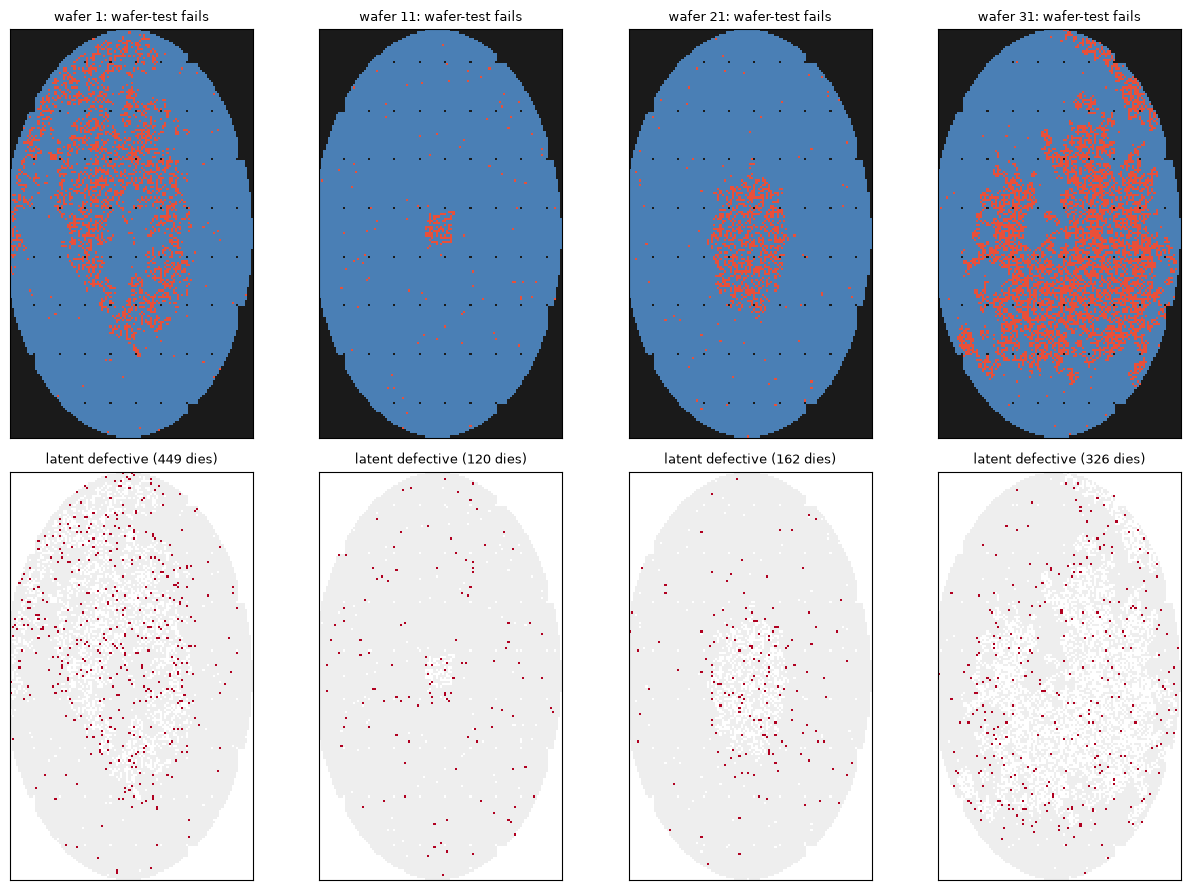

In [5]:
show = [0, 10, 20, 30]
fig, ax = plt.subplots(2, len(show), figsize=(3.2 * len(show), 9))
for j, i in enumerate(show):
    show_failmap(ax[0, j], ws, i)
    show_latent(ax[1, j], ws, i)
plt.tight_layout()
plt.show()

## 3 · Baselines (slide 7)
| Role | Method | Score per passing die |
|---|---|---|
| Simple model | Random | uniform random number |
| Engineering reference | Distance to fail | minus the distance to the nearest wafer-test fail |
| Engineering reference | Wafer-level fallback | the wafer's fail fraction (whole wafer burned in together) |
| Simple model | Neighbor z-score | largest robust residual of any parameter vs. its 5×5 neighbours |
| Simple model | Hotelling T² (PCA) | multivariate T² of the 5 parameters (Modules 2 and 6) |
| Simple model | Feature GBM | gradient boosting on hand-built features: distance to fail, fail density at radius 1/2/4/8, wafer fail fraction, radius, abs z, T², neighbour residual |

"Burn in every die" is the cost ceiling (100% burned in, 100% recall) and needs no score.

Everything fitted (normaliser, T², GBM) is fitted on 3 lots and scored on the 4th (LOLO), so every
score below is out-of-fold.

In [6]:
oof = lolo_baselines(ws)
table, curves = compare(oof, ws)
table.round(3)

fold Lot_1 done


fold Lot_2 done


fold Lot_3 done


fold Lot_4 done


,recall@5%burn,recall@10%burn,recall@20%burn,burn%@80%recall,burn%@90%recall,AUC,AP,DPPM@10%burn
method,,,,,,,,
Random,0.049,0.100,0.199,0.800,0.901,0.500,0.014,12844.612
Distance to fail,0.165,0.330,0.551,0.516,0.745,0.721,0.036,9591.158
Wafer-level fallback,0.162,0.287,0.460,0.569,0.751,0.684,0.032,10202.473
Neighbor z-score,0.355,0.450,0.567,0.547,0.754,0.736,0.155,7884.658
Hotelling T2 (PCA),0.392,0.480,0.588,0.532,0.744,0.748,0.216,7465.973
Feature GBM,0.475,0.593,0.754,0.247,0.479,0.846,0.279,5849.091


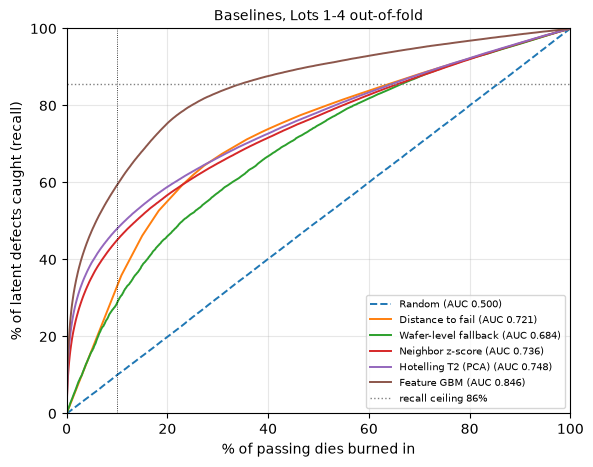

In [7]:
plot_curves(curves, ceiling=CEILING, title="Baselines, Lots 1-4 out-of-fold")
plt.show()

Per-lot spread of recall at 10% burn-in (how stable each method is across lots):

In [8]:
per_lot = pd.DataFrame({name: {lot: screening_curve(s[ws.lot == lot], ws.latent[ws.lot == lot],
                                                      ws.passing[ws.lot == lot]).recall_at(0.10)
                               for lot in TRAIN_LOTS} for name, s in oof.items()}).T
per_lot["mean"], per_lot["std"] = per_lot.mean(axis=1), per_lot.std(axis=1)
per_lot.round(3)

,Lot_1,Lot_2,Lot_3,Lot_4,mean,std
Random,0.099,0.100,0.100,0.101,0.100,0.001
Distance to fail,0.324,0.315,0.346,0.335,0.330,0.013
Wafer-level fallback,0.301,0.281,0.284,0.286,0.288,0.009
Neighbor z-score,0.444,0.442,0.459,0.457,0.451,0.009
Hotelling T2 (PCA),0.474,0.472,0.488,0.486,0.480,0.008
Feature GBM,0.587,0.585,0.605,0.594,0.593,0.009


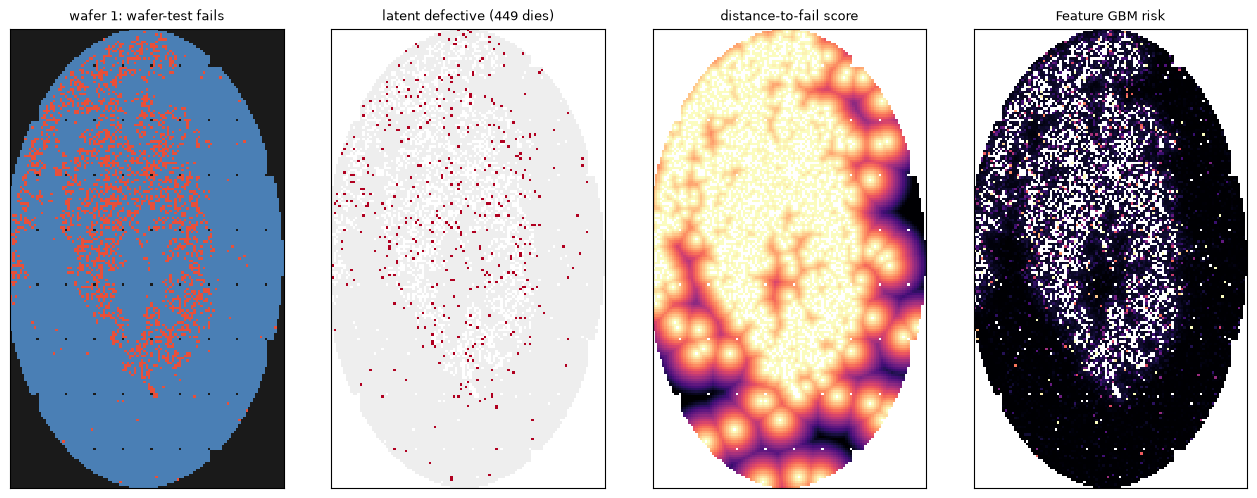

In [9]:
i = 0
fig, ax = plt.subplots(1, 4, figsize=(13, 5))
show_failmap(ax[0], ws, i)
show_latent(ax[1], ws, i)
show_risk(ax[2], ws, i, oof["Distance to fail"], "distance-to-fail score")
show_risk(ax[3], ws, i, oof["Feature GBM"], "Feature GBM risk")
plt.tight_layout()
plt.show()

## 4 · Save out-of-fold baseline scores for notebook 04

In [10]:
out = P.results / "oof_baselines.npz"
np.savez_compressed(out, wafer=ws.wafer, **{k: v.astype(np.float32) for k, v in oof.items()})
table.to_csv(P.results / "oof_baselines_table.csv")
print("saved", out)

saved C:\Users\nsaba\OneDrive - Analog Devices, Inc\Documents\Chipagents\8803\Project\results\sim_full\oof_baselines.npz
